# 06 · Precios de Yahoo: cobertura, inicio y calidad (bloque 6)

Este notebook recorre el **núcleo de precios** descargado con `yfinance` (0.2.66) por
`ingesta.mercados_series.proveedores.yahoo`: los 42 ETF de la propuesta, AGG, RSP, VBMFX, IBIT y ETHA,
16 índices, 4 divisas, 5 futuros de contexto y 20 acciones grandes de EE. UU., Europa y Asia.

Cada ticker se guarda **as-traded** (precios tal como cotizaron: se deshacen los splits que Yahoo aplica hacia
atrás; `Adj Close` nunca se guarda) en `<corpus>/mercados_series/precios/yahoo/<ticker>.parquet`, con
`fecha_publicacion` = primera decisión (16:30 de Nueva York) tras el cierre local + 30 min. El ajuste por splits y
dividendos se reconstruye **a fecha** con `timegate.ajustar_a_fecha`.

Los precios viven fuera del repositorio (términos de Yahoo: solo local). Con `EJECUTAR = False` el notebook solo lee
el registro del lote y los parquet; para descargar: `python -m ingesta.mercados_series.proveedores.yahoo nucleo`
(reanudable). Las salidas **no muestran tablas de precios**: recuentos, fechas y gráficos.

Secciones:

1. Qué se ha bajado: instrumentos por clase y mercado.
2. Inicio y fin por instrumento.
3. El efecto «Yahoo empieza hacia 2000».
4. Mapa de cobertura por mercado y año.
5. Calidad: saltos sin split, volumen cero, cierres repetidos y dividendos altos.
6. As-traded frente a ajustado a fecha (AAPL y NVDA).
7. Retraso de publicación por mercado.

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from ingesta.mercados_series import almacen, calidad, timegate
from ingesta.mercados_series.proveedores import yahoo

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)

EJECUTAR = False   # True: descarga (o completa) el núcleo antes de leerlo (unos 5 minutos)
if EJECUTAR:
    yahoo.descargar_lote(yahoo.NUCLEO, etiqueta='nucleo')
REG = yahoo.leer_registro('nucleo').drop_duplicates('ticker', keep='last')
if REG.empty:
    raise FileNotFoundError('Sin registro del núcleo: python -m ingesta.mercados_series.proveedores.yahoo nucleo')
OK = REG[REG['estado'] == 'ok'].copy()
OK['inicio'] = pd.to_datetime(OK['inicio'])
OK['fin'] = pd.to_datetime(OK['fin'])
OK['primera_cotizacion'] = pd.to_datetime(OK['primera_cotizacion'])
CLASES = {'ETF': '#2a78d6', 'EQUITY': '#d6612a', 'INDEX': '#3a9e5c', 'CURRENCY': '#8e5cc2',
          'FUTURE': '#b8a03a', 'MUTUALFUND': '#7a7a7a'}
with yahoo.mercados_con_fragmentos():   # sin fragmentos pendientes: equivale a mercados.yaml
    PRECIOS = pd.concat([almacen.leer_precios(t, 'yahoo') for t in OK['ticker']], ignore_index=True)
print(f'{len(REG)} tickers pedidos: {len(OK)} guardados, {int((REG["estado"] != "ok").sum())} con error; '
      f'{len(PRECIOS):,} sesiones en total')

92 tickers pedidos: 92 guardados, 0 con error; 657,499 sesiones en total


## 1. Qué se ha bajado

Clase (`instrumentType` de Yahoo) y mercado (clave de `config/mercados.yaml` o de los fragmentos) de cada
instrumento. Los ETF de EE. UU. cotizan casi todos en NYSE Arca (`ARCX`); los de Nasdaq (QQQ, IBIT, ETHA...) en
`XNAS`. Las divisas usan la vela diaria de Yahoo (`FX_YAHOO`, cierre a medianoche de Londres) y los futuros la
de CME Globex: ambas visibles en la decisión del día siguiente.

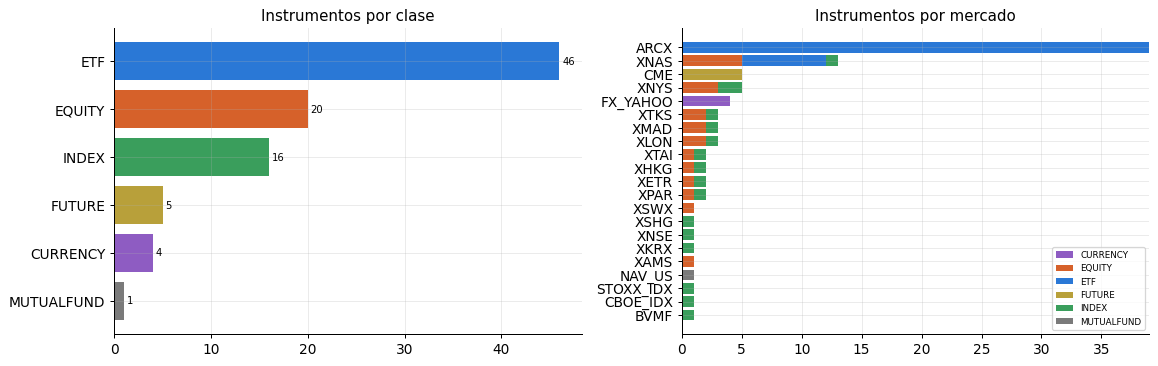

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
n = OK['clase'].value_counts().sort_values()
axes[0].barh(n.index, n.values, color=[CLASES.get(k, '#999') for k in n.index])
axes[0].set_title('Instrumentos por clase')
for i, v in enumerate(n.values):
    axes[0].text(v + 0.3, i, str(v), va='center', fontsize=8)
tabla = OK.groupby(['mercado', 'clase']).size().unstack(fill_value=0)
tabla = tabla.loc[tabla.sum(axis=1).sort_values().index]
izq = np.zeros(len(tabla))
for cl in tabla.columns:
    axes[1].barh(tabla.index, tabla[cl], left=izq, color=CLASES.get(cl, '#999'), label=cl)
    izq += tabla[cl].to_numpy()
axes[1].set_title('Instrumentos por mercado')
axes[1].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()
if (REG['estado'] != 'ok').any():
    print('Errores:', REG.loc[REG['estado'] != 'ok', ['ticker', 'error']].to_dict('records'))

## 2. Inicio y fin por instrumento

Cada barra va del primer al último cierre guardado. El rombo marca `firstTradeDate` de los metadatos de Yahoo: si
la historia empezase mucho después, el proveedor reintenta con `start` explícito y, si sigue recortada, lo avisa
(nunca se recorta en silencio).

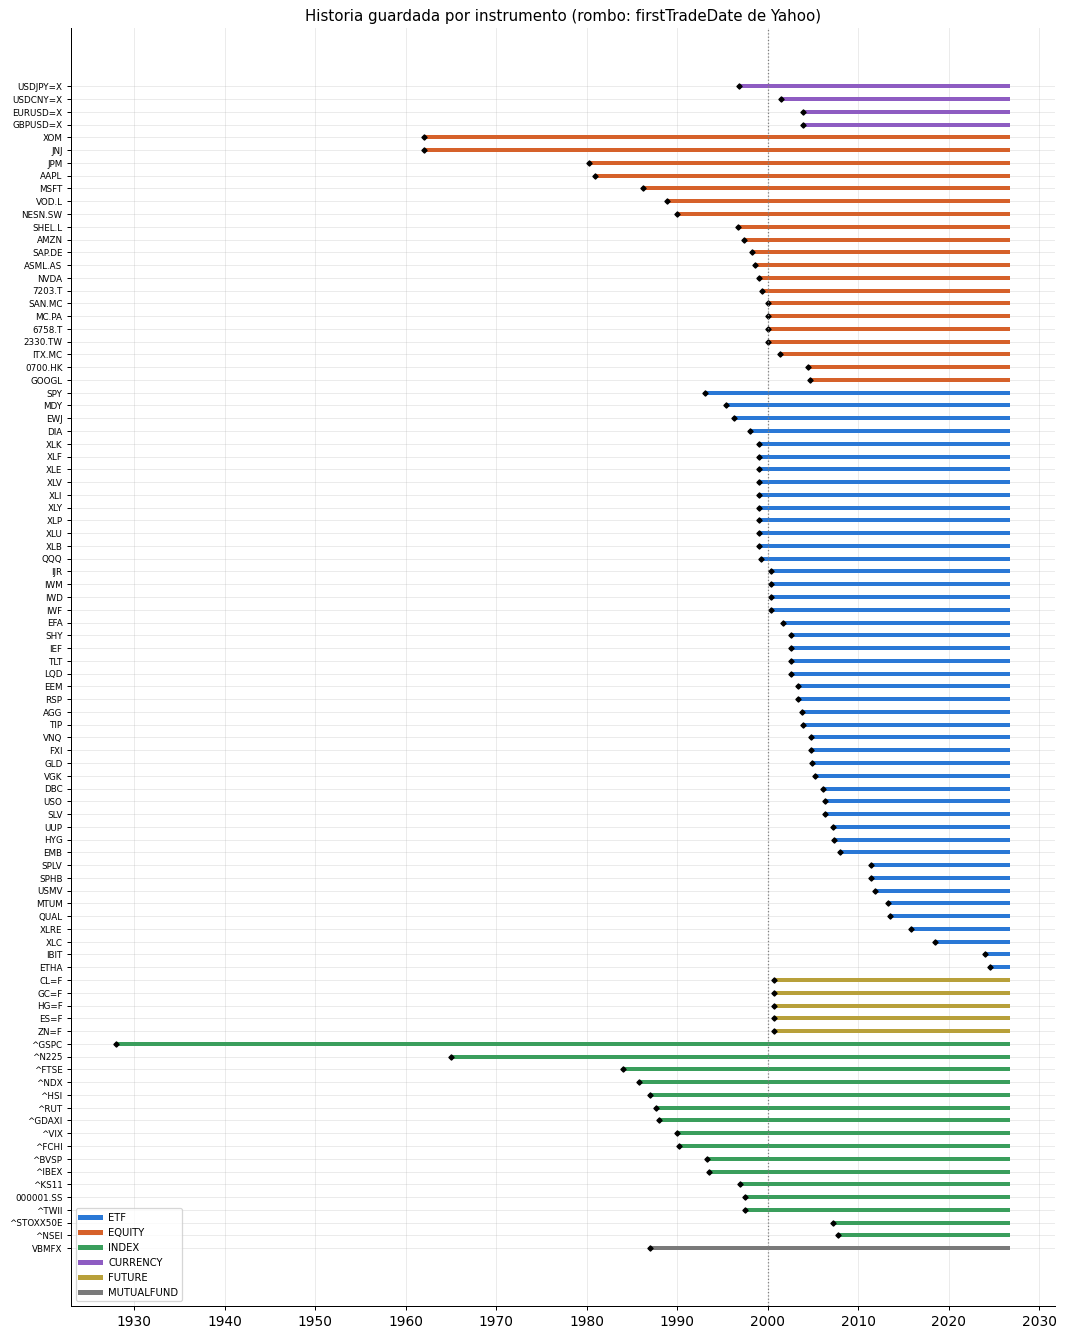

Tickers con aviso de inicio: 0 []


In [3]:
o = OK.sort_values(['clase', 'inicio']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 15))
for i, r in o.iterrows():
    ax.plot([r['inicio'], r['fin']], [i, i], color=CLASES.get(r['clase'], '#999'), lw=3.2, solid_capstyle='butt')
    if pd.notna(r['primera_cotizacion']):
        ax.plot(r['primera_cotizacion'], i, marker='D', ms=3, color='black')
ax.set_yticks(range(len(o)))
ax.set_yticklabels(o['ticker'], fontsize=7)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator(10))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.axvline(pd.Timestamp('2000-01-01'), color='grey', ls=':', lw=1)
for cl, col in CLASES.items():
    ax.plot([], [], color=col, lw=4, label=cl)
ax.legend(fontsize=8, loc='lower left')
ax.set_title('Historia guardada por instrumento (rombo: firstTradeDate de Yahoo)')
plt.tight_layout()
plt.show()
avisos = OK[OK['avisos'].map(lambda x: isinstance(x, list) and len(x) > 0)]
print(f'Tickers con aviso de inicio: {len(avisos)}', list(avisos['ticker']))

## 3. El efecto «Yahoo empieza hacia 2000»

Yahoo no tiene la historia completa de muchos índices y acciones fuera de EE. UU.: el DAX, el CAC 40, el IBEX,
el Hang Seng o el Nikkei arrancan en los años noventa aunque los índices existan desde mucho antes, y el EURO STOXX
50 solo desde 2007. Para el backtest 2000-2024 casi todo está, pero los periodos de entrenamiento largos (crisis de
los setenta y ochenta) solo los cubren los índices de EE. UU. y las fuentes académicas (Shiller, French).

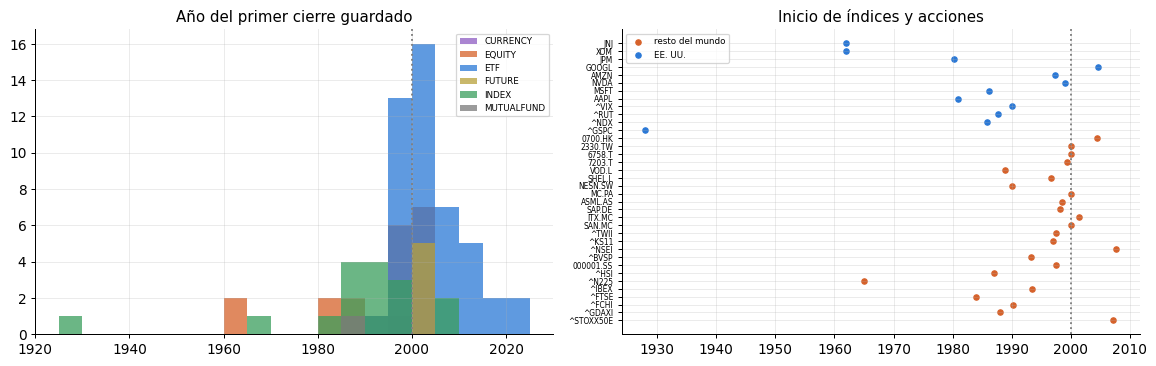

Resto: mediana de inicio 1997-07-02, 67% antes de 2000
EE. UU.: mediana de inicio 1985-12-21, 92% antes de 2000


In [4]:
o = OK.copy()
o['anio'] = o['inicio'].dt.year
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.arange(1925, 2030, 5)
for cl, g in o.groupby('clase'):
    axes[0].hist(g['anio'], bins=bins, alpha=0.75, label=cl, color=CLASES.get(cl, '#999'))
axes[0].axvline(2000, color='grey', ls=':')
axes[0].set_title('Año del primer cierre guardado')
axes[0].legend(fontsize=7)
fuera = o[o['clase'].isin(['INDEX', 'EQUITY'])].copy()
fuera['eeuu'] = fuera['mercado'].isin(['XNYS', 'XNAS', 'ARCX', 'CBOE_IDX'])
for ee, g in fuera.groupby('eeuu'):
    axes[1].scatter(g['inicio'], g['ticker'], s=18, label='EE. UU.' if ee else 'resto del mundo',
                    color='#2a78d6' if ee else '#d6612a')
axes[1].axvline(pd.Timestamp('2000-01-01'), color='grey', ls=':')
axes[1].tick_params(axis='y', labelsize=6)
axes[1].set_title('Inicio de índices y acciones')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()
for ee, g in fuera.groupby('eeuu'):
    print(f"{'EE. UU.' if ee else 'Resto'}: mediana de inicio {g['inicio'].median().date()}, "
          f"{(g['inicio'] < '2000-01-01').mean():.0%} antes de 2000")

## 4. Mapa de cobertura por mercado y año

Número de instrumentos con al menos un cierre en cada año, por mercado. La ampliación del universo
(~1.700 instrumentos, constituyentes de índices) rellenará sobre todo los mercados europeos y asiáticos.

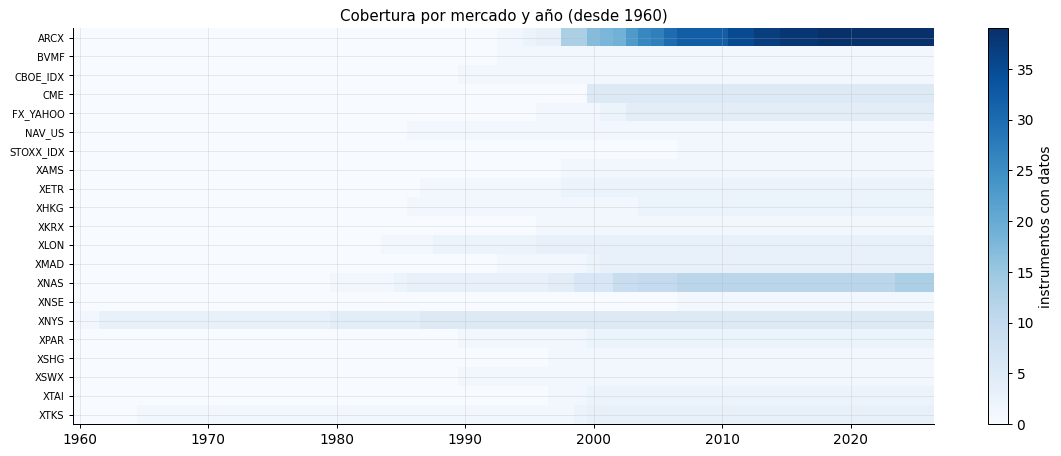

In [5]:
anios = PRECIOS.assign(anio=PRECIOS['sesion'].dt.year)[['ticker', 'mercado', 'anio']].drop_duplicates()
mapa = anios.groupby(['mercado', 'anio'])['ticker'].nunique().unstack(fill_value=0)
mapa = mapa.loc[:, mapa.columns >= 1960]
fig, ax = plt.subplots(figsize=(13, 5.2))
im = ax.imshow(mapa.to_numpy(), aspect='auto', cmap='Blues', interpolation='nearest')
ax.set_yticks(range(len(mapa)))
ax.set_yticklabels(mapa.index, fontsize=8)
xt = [i for i, a in enumerate(mapa.columns) if a % 10 == 0]
ax.set_xticks(xt)
ax.set_xticklabels([mapa.columns[i] for i in xt])
plt.colorbar(im, ax=ax, label='instrumentos con datos')
ax.set_title('Cobertura por mercado y año (desde 1960)')
plt.tight_layout()
plt.show()

## 5. Calidad

`calidad.incidencias_precios` marca, sin corregir nada: saltos de más del 40 % en un día sin split (con el split
deshecho), volumen cero (salvo índices, divisas y fondos), cierres idénticos al del día anterior y dividendos de más
del 20 % del cierre previo. Los cierres repetidos son normales en series antiguas de Yahoo (precios rellenados) y
en fondos de renta fija; los saltos suelen ser splits ausentes o errores del proveedor.

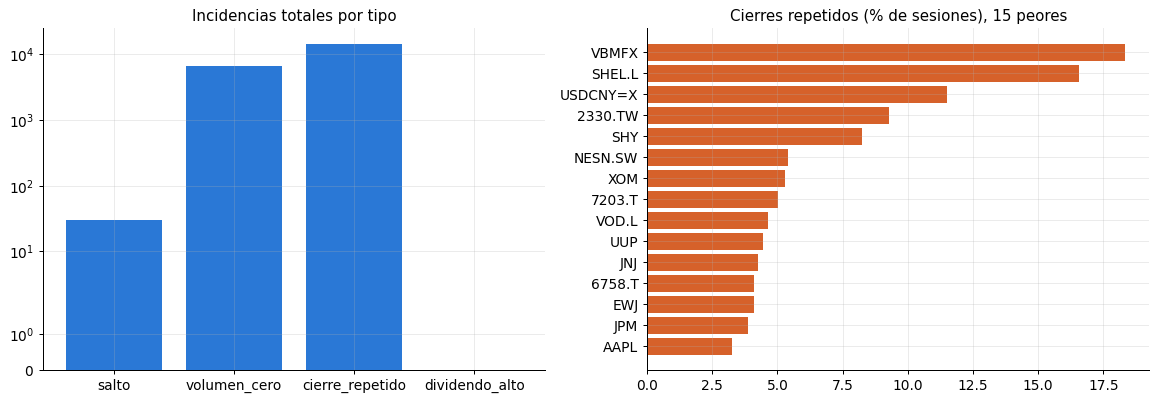

salto: 30 sesiones en 6 tickers: ['AAPL', 'ASML.AS', 'CL=F', 'NVDA', 'SHEL.L', '^VIX']
dividendo_alto: 0 sesiones en 0 tickers: []
  XLF: splits fraccionarios (1 < ratio < 1,5; dividendos en acciones) en 1 sesiones, p. ej. ['2016-09-19']
  EWJ: contra-splits/consolidaciones (ratio < 1) en ['2016-11-07']
  USO: contra-splits/consolidaciones (ratio < 1) en ['2020-04-29']
  ETHA: contra-splits/consolidaciones (ratio < 1) en ['2026-10-06']
  SAN.MC: splits fraccionarios (1 < ratio < 1,5; dividendos en acciones) en 2 sesiones, p. ej. ['2011-01-17', '2020-11-16']
  ASML.AS: contra-splits/consolidaciones (ratio < 1) en ['2007-10-01', '2012-11-26']
  VOD.L: contra-splits/consolidaciones (ratio < 1) en ['2006-07-31', '2014-02-24']
  2330.TW: splits fraccionarios (1 < ratio < 1,5; dividendos en acciones) en 10 sesiones, p. ej. ['2000-05-15', '2001-06-26', '2002-06-19']


In [6]:
clases = dict(zip(OK['ticker'], OK['clase']))
RES = calidad.resumen_calidad(PRECIOS, clases)
tot = RES[list(calidad.TIPOS)].sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].bar(tot.index, tot.values, color='#2a78d6')
axes[0].set_title('Incidencias totales por tipo')
axes[0].set_yscale('symlog')
peor = (RES['cierre_repetido'] / RES['sesiones']).sort_values().tail(15)
axes[1].barh(peor.index, peor.values * 100, color='#d6612a')
axes[1].set_title('Cierres repetidos (% de sesiones), 15 peores')
plt.tight_layout()
plt.show()
inc = calidad.incidencias_precios(PRECIOS, clases)
for tipo in ('salto', 'dividendo_alto'):
    d = inc[inc['tipo'] == tipo]
    print(f'{tipo}: {len(d)} sesiones en {d["ticker"].nunique()} tickers:', sorted(d['ticker'].unique())[:20])
notas = OK[OK['notas'].map(lambda x: isinstance(x, list) and len(x) > 0)]
for r in notas.itertuples():
    print(f'  {r.ticker}: ' + ' | '.join(r.notas))

## 6. As-traded frente a ajustado a fecha

AAPL (splits 2:1 en 1987, 2000 y 2005, 7:1 en 2014 y 4:1 en 2020) y NVDA (10:1 en 2024): el cierre as-traded
salta en cada split; `ajustar_a_fecha(hoy)` reconstruye el `Adj Close` de Yahoo (test `live`), y con una fecha
pasada solo usa los splits y dividendos conocidos entonces. Escala logarítmica, cierres en dólares.

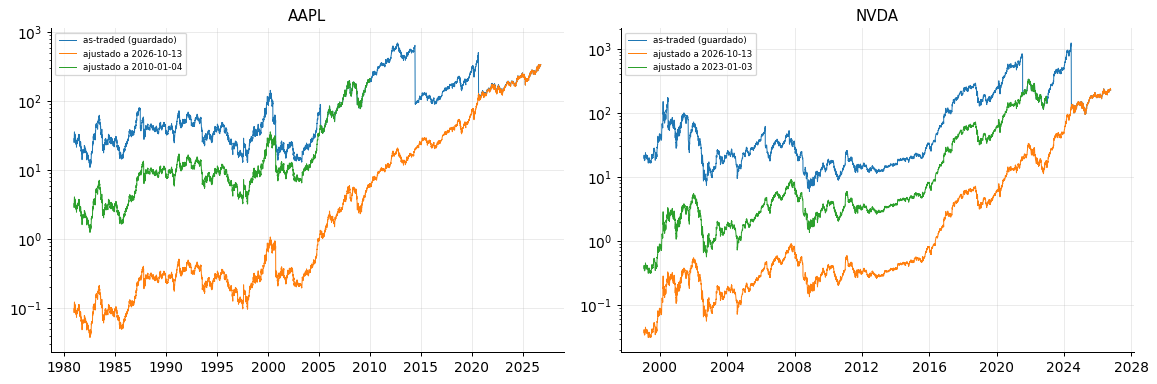

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
hoy = pd.Timestamp.now(tz='America/New_York').date()
for ax, tk, pasado in ((axes[0], 'AAPL', '2010-01-04'), (axes[1], 'NVDA', '2023-01-03')):
    p = PRECIOS[PRECIOS['ticker'] == tk]
    with yahoo.mercados_con_fragmentos():
        aj = timegate.ajustar_a_fecha(p, hoy)
        aj_pasado = timegate.ajustar_a_fecha(p, pasado)
    ax.plot(p['sesion'], p['close'], lw=0.8, label='as-traded (guardado)')
    ax.plot(aj['sesion'], aj['close_aj_total'], lw=0.8, label=f'ajustado a {hoy}')
    ax.plot(aj_pasado['sesion'], aj_pasado['close_aj_total'], lw=0.8, label=f'ajustado a {pasado}')
    ax.set_yscale('log')
    ax.set_title(tk)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 7. Retraso de publicación por mercado

Días entre la sesión y su `fecha_publicacion` (primera decisión de las 16:30 de Nueva York tras el cierre local +
30 min). Europa y Asia se ven el mismo día; EE. UU. también (16:00 + 30 min = 16:30); el VIX (16:15), los futuros
de CME, las divisas de Yahoo y el NAV de los fondos, al día siguiente (o tras el fin de semana).

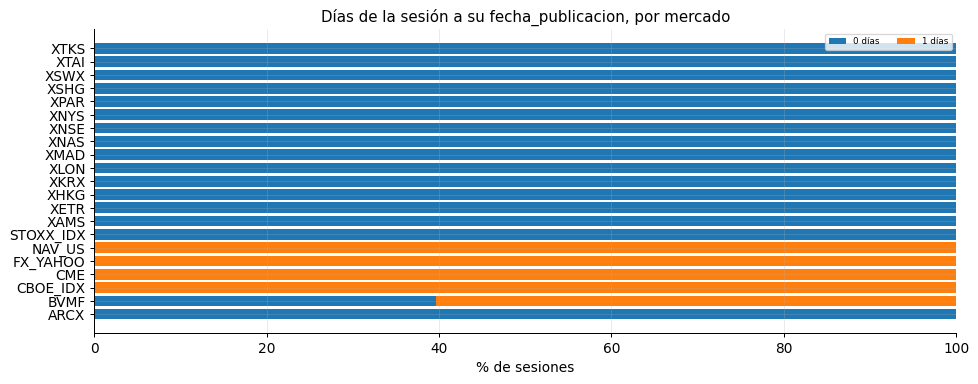

In [8]:
d = PRECIOS.assign(dias=(PRECIOS['fecha_publicacion'] - PRECIOS['sesion']).dt.days)
tabla = d.groupby('mercado')['dias'].value_counts(normalize=True).unstack(fill_value=0) * 100
fig, ax = plt.subplots(figsize=(11, 4.4))
izq = np.zeros(len(tabla))
for k in tabla.columns:
    ax.barh(tabla.index, tabla[k], left=izq, label=f'{k} días')
    izq += tabla[k].to_numpy()
ax.set_xlabel('% de sesiones')
ax.legend(fontsize=7, ncol=4)
ax.set_title('Días de la sesión a su fecha_publicacion, por mercado')
plt.tight_layout()
plt.show()